In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import pickle
import os
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [3]:
df = pd.read_csv(r"combined_dataset (1).csv")
df

,frame.time_delta,frame.time_relative,frame.len,tcp.srcport,tcp.dstport,tcp.len,tcp.ack,tcp.connection.fin,tcp.connection.rst,tcp.connection.sack,...,mqtt.msgtype,mqtt.qos,mqtt.retain,mqtt.topic,mqtt.topic_len,mqtt.ver,mqtt.willmsg_len,ip.proto,ip.ttl,category
0,0.000000,0.000000,74,56808,1883,0,0,0,0,0,...,0,0,0,0,0,0,0,6,64,Attack
1,0.000052,0.000052,74,1883,56808,0,1,0,0,1,...,0,0,0,0,0,0,0,6,64,Attack
2,0.000008,0.000060,74,56810,1883,0,0,0,0,0,...,0,0,0,0,0,0,0,6,64,Attack
3,0.000012,0.000072,74,1883,56810,0,1,0,0,1,...,0,0,0,0,0,0,0,6,64,Attack
4,0.000003,0.000075,74,56812,1883,0,0,0,0,0,...,0,0,0,0,0,0,0,6,64,Attack
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188689,0.000008,2047.246123,80,37239,1883,12,73,0,0,0,...,3,0,0,CoGas,5,0,0,6,64,No_Attack
188690,0.000058,2047.246181,72,1883,44939,4,8302,0,0,0,...,4,0,0,0,0,0,0,6,64,No_Attack
188691,0.000011,2047.246192,72,1883,44853,4,7619,0,0,0,...,4,0,0,0,0,0,0,6,64,No_Attack
188692,0.000010,2047.246202,72,1883,37361,4,8302,0,0,0,...,4,0,0,0,0,0,0,6,64,No_Attack


In [4]:
df['category'].unique()

array(['Attack', 'No_Attack'], dtype=object)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188694 entries, 0 to 188693
Data columns (total 40 columns):
frame.time_delta         188694 non-null float64
frame.time_relative      188694 non-null float64
frame.len                188694 non-null int64
tcp.srcport              188694 non-null int64
tcp.dstport              188694 non-null int64
tcp.len                  188694 non-null int64
tcp.ack                  188694 non-null int64
tcp.connection.fin       188694 non-null int64
tcp.connection.rst       188694 non-null int64
tcp.connection.sack      188694 non-null int64
tcp.connection.syn       188694 non-null int64
tcp.flags.ack            188694 non-null int64
tcp.flags.fin            188694 non-null int64
tcp.flags.push           188694 non-null int64
tcp.flags.reset          188694 non-null int64
tcp.flags.syn            188694 non-null int64
tcp.flags.urg            188694 non-null int64
tcp.hdr_len              188694 non-null int64
tcp.pdu.size             188694 non-nul

In [6]:
df.isnull().sum()

frame.time_delta         0
frame.time_relative      0
frame.len                0
tcp.srcport              0
tcp.dstport              0
tcp.len                  0
tcp.ack                  0
tcp.connection.fin       0
tcp.connection.rst       0
tcp.connection.sack      0
tcp.connection.syn       0
tcp.flags.ack            0
tcp.flags.fin            0
tcp.flags.push           0
tcp.flags.reset          0
tcp.flags.syn            0
tcp.flags.urg            0
tcp.hdr_len              0
tcp.pdu.size             0
tcp.window_size_value    0
mqtt.clientid_len        0
mqtt.conack.val          0
mqtt.conflag.passwd      0
mqtt.conflag.qos         0
mqtt.conflag.reserved    0
mqtt.conflag.retain      0
mqtt.conflag.willflag    0
mqtt.dupflag             0
mqtt.kalive              0
mqtt.len                 0
mqtt.msgtype             0
mqtt.qos                 0
mqtt.retain              0
mqtt.topic               0
mqtt.topic_len           0
mqtt.ver                 0
mqtt.willmsg_len         0
i

In [7]:
df.duplicated().sum()

2

In [8]:
df.nunique()

frame.time_delta          11692
frame.time_relative      176587
frame.len                   633
tcp.srcport                2062
tcp.dstport                2062
tcp.len                     638
tcp.ack                   26555
tcp.connection.fin            2
tcp.connection.rst            2
tcp.connection.sack           2
tcp.connection.syn            2
tcp.flags.ack                 2
tcp.flags.fin                 2
tcp.flags.push                2
tcp.flags.reset               2
tcp.flags.syn                 2
tcp.flags.urg                 1
tcp.hdr_len                   4
tcp.pdu.size                 84
tcp.window_size_value        57
mqtt.clientid_len             9
mqtt.conack.val               1
mqtt.conflag.passwd           1
mqtt.conflag.qos              1
mqtt.conflag.reserved         1
mqtt.conflag.retain           1
mqtt.conflag.willflag         1
mqtt.dupflag                  2
mqtt.kalive                   7
mqtt.len                     83
mqtt.msgtype                 11
mqtt.qos

In [9]:
le = LabelEncoder()
df['category'] = le.fit_transform(df['category'])
df['mqtt.topic'] = le.fit_transform(df['mqtt.topic'])
df

,frame.time_delta,frame.time_relative,frame.len,tcp.srcport,tcp.dstport,tcp.len,tcp.ack,tcp.connection.fin,tcp.connection.rst,tcp.connection.sack,...,mqtt.msgtype,mqtt.qos,mqtt.retain,mqtt.topic,mqtt.topic_len,mqtt.ver,mqtt.willmsg_len,ip.proto,ip.ttl,category
0,0.000000,0.000000,74,56808,1883,0,0,0,0,0,...,0,0,0,49,0,0,0,6,64,0
1,0.000052,0.000052,74,1883,56808,0,1,0,0,1,...,0,0,0,49,0,0,0,6,64,0
2,0.000008,0.000060,74,56810,1883,0,0,0,0,0,...,0,0,0,49,0,0,0,6,64,0
3,0.000012,0.000072,74,1883,56810,0,1,0,0,1,...,0,0,0,49,0,0,0,6,64,0
4,0.000003,0.000075,74,56812,1883,0,0,0,0,0,...,0,0,0,49,0,0,0,6,64,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188689,0.000008,2047.246123,80,37239,1883,12,73,0,0,0,...,3,0,0,53,5,0,0,6,64,1
188690,0.000058,2047.246181,72,1883,44939,4,8302,0,0,0,...,4,0,0,49,0,0,0,6,64,1
188691,0.000011,2047.246192,72,1883,44853,4,7619,0,0,0,...,4,0,0,49,0,0,0,6,64,1
188692,0.000010,2047.246202,72,1883,37361,4,8302,0,0,0,...,4,0,0,49,0,0,0,6,64,1


In [10]:
x = df.drop(['category'],axis=1)
x

,frame.time_delta,frame.time_relative,frame.len,tcp.srcport,tcp.dstport,tcp.len,tcp.ack,tcp.connection.fin,tcp.connection.rst,tcp.connection.sack,...,mqtt.len,mqtt.msgtype,mqtt.qos,mqtt.retain,mqtt.topic,mqtt.topic_len,mqtt.ver,mqtt.willmsg_len,ip.proto,ip.ttl
0,0.000000,0.000000,74,56808,1883,0,0,0,0,0,...,0,0,0,0,49,0,0,0,6,64
1,0.000052,0.000052,74,1883,56808,0,1,0,0,1,...,0,0,0,0,49,0,0,0,6,64
2,0.000008,0.000060,74,56810,1883,0,0,0,0,0,...,0,0,0,0,49,0,0,0,6,64
3,0.000012,0.000072,74,1883,56810,0,1,0,0,1,...,0,0,0,0,49,0,0,0,6,64
4,0.000003,0.000075,74,56812,1883,0,0,0,0,0,...,0,0,0,0,49,0,0,0,6,64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188689,0.000008,2047.246123,80,37239,1883,12,73,0,0,0,...,10,3,0,0,53,5,0,0,6,64
188690,0.000058,2047.246181,72,1883,44939,4,8302,0,0,0,...,2,4,0,0,49,0,0,0,6,64
188691,0.000011,2047.246192,72,1883,44853,4,7619,0,0,0,...,2,4,0,0,49,0,0,0,6,64
188692,0.000010,2047.246202,72,1883,37361,4,8302,0,0,0,...,2,4,0,0,49,0,0,0,6,64


In [11]:
y = df['category']
y

0         0
1         0
2         0
3         0
4         0
         ..
188689    1
188690    1
188691    1
188692    1
188693    1
Name: category, Length: 188694, dtype: int32

<AxesSubplot:xlabel='category', ylabel='count'>

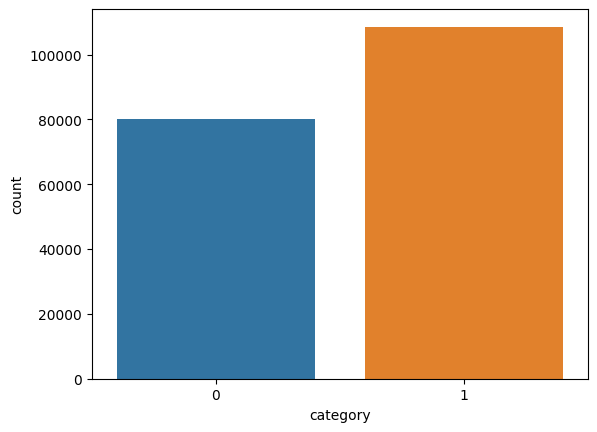

In [12]:
sns.countplot(x=y)

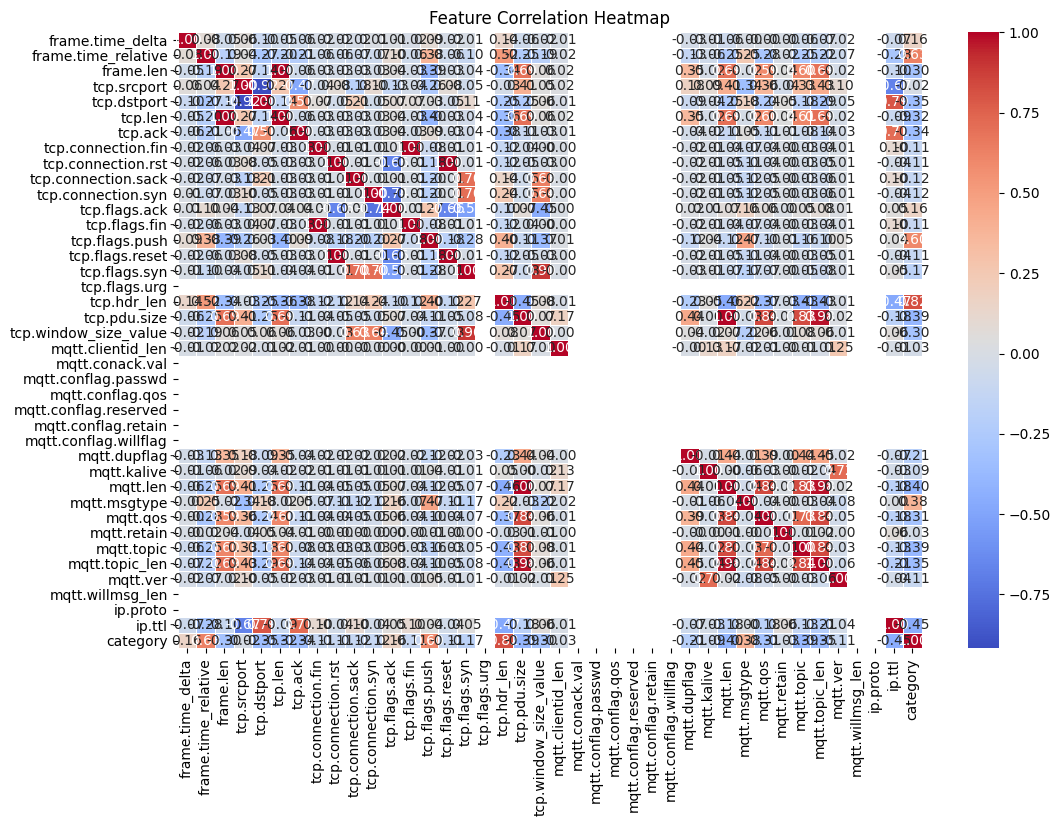

In [13]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Show the heatmap
plt.title("Feature Correlation Heatmap")
plt.show()

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42)



In [15]:
x_train.shape

(150955, 39)

In [16]:
x_test.shape

(37739, 39)

In [17]:
y_train.shape

(150955,)

In [18]:
y_test.shape

(37739,)

In [19]:
labels = ['Attack' , 'No_Attack']

In [20]:
precision = []
recall = []
fscore = []
accuracy = []

#function to calculate various metrics such as accuracy, precision etc
def PerformanceMetrics(algorithm, predict, testY):
    testY = testY.astype('int')
    predict = predict.astype('int')
    p = precision_score(testY, predict,average='macro') * 100
    r = recall_score(testY, predict,average='macro') * 100
    f = f1_score(testY, predict,average='macro') * 100
    a = accuracy_score(testY,predict)*100 
    accuracy.append(a)
    precision.append(p)
    recall.append(r)
    fscore.append(f)
    print(algorithm+' Accuracy    : '+str(a))
    print(algorithm+' Precision   : '+str(p))
    print(algorithm+' Recall      : '+str(r))
    print(algorithm+' FSCORE      : '+str(f))
    print(f"\n{algorithm} Classification Report:\n")
    print(classification_report(testY, predict, target_names=labels))
    conf_matrix = confusion_matrix(testY, predict) 
    plt.figure(figsize =(5, 5)) 
    ax = sns.heatmap(conf_matrix, xticklabels = labels, yticklabels = labels, annot = True, cmap="Blues" ,fmt ="g");
    ax.set_ylim([0,len(labels)])
    plt.title(algorithm+" Confusion matrix") 
    plt.ylabel('True class') 
    plt.xlabel('Predicted class') 
    plt.show()

Logistic Regression Accuracy    : 83.52102599432948
Logistic Regression Precision   : 83.27967602585555
Logistic Regression Recall      : 82.85290288739446
Logistic Regression FSCORE      : 83.03557646199981

Logistic Regression Classification Report:

              precision    recall  f1-score   support

      Attack       0.82      0.78      0.80     16027
   No_Attack       0.85      0.87      0.86     21712

    accuracy                           0.84     37739
   macro avg       0.83      0.83      0.83     37739
weighted avg       0.83      0.84      0.83     37739



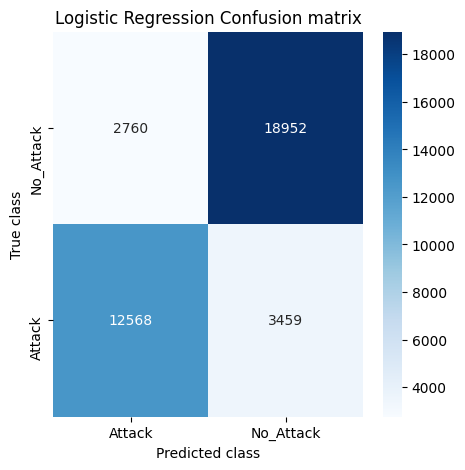

In [21]:
from sklearn.linear_model import LogisticRegression
model = 'logistic_regression.pkl'
if os.path.exists(model):
    # Load the model from the pkl file
    logistic_regression = joblib.load(model)
    predict = logistic_regression.predict(x_test)
    PerformanceMetrics("Logistic Regression", predict, y_test)
else:
    logistic_regression = LogisticRegression(max_iter=1)
    # Train the classifier on the training data
    logistic_regression.fit(x_train, y_train)
    # Make predictions on the test data
    predict = logistic_regression.predict(x_test)
    joblib.dump(logistic_regression, model)
    print("Logistic Regression trained and model weights saved.")
    PerformanceMetrics("Logistic Regression", predict, y_test)

Random Forest Accuracy    : 100.0
Random Forest Precision   : 100.0
Random Forest Recall      : 100.0
Random Forest FSCORE      : 100.0

Random Forest Classification Report:

              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     16027
   No_Attack       1.00      1.00      1.00     21712

    accuracy                           1.00     37739
   macro avg       1.00      1.00      1.00     37739
weighted avg       1.00      1.00      1.00     37739



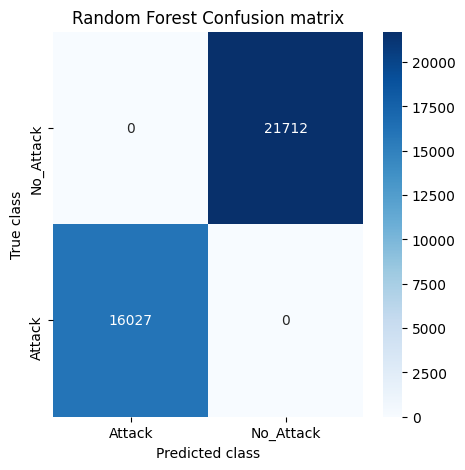

In [22]:
model = 'random_forest.pkl'
if os.path.exists(model):
    # Load the model from the pkl file
    random_forest = joblib.load(model)
    predict = random_forest.predict(x_test)
    PerformanceMetrics("Random Forest", predict, y_test)
else:
    random_forest = RandomForestClassifier()
    # Train the classifier on the training data
    random_forest.fit(x_train, y_train)
    # Make predictions on the test data
    predict = random_forest.predict(x_test)
    joblib.dump(random_forest, model)
    print("Random Forest trained and model weights saved.")
    PerformanceMetrics("Random Forest", predict, y_test)
